# Waste Image Classification — BDC Satria Data 2026

**Problem:** Klasifikasi citra limbah/sampah ke dalam 3 kategori — `Recyclable`, `Electronic`, `Organic` — untuk mendukung sistem pemilahan sampah otomatis. Dinilai dengan **Macro-averaged F1-Score**.

**Approach (base pipeline diadaptasi dari kompetisi anti-spoofing sebelumnya):**
- Transfer learning dari 3 pretrained backbone: ConvNeXt-Small, EfficientNet-B3, EfficientNetV2-S
- K-Fold Stratified CV + SWA (Izmailov et al., 2018) untuk stabilitas & generalisasi
- Augmentasi umum untuk citra objek (bukan face-specific): flip, rotasi ringan, color jitter, noise/blur, coarse dropout — supaya model belajar tekstur & bentuk material (plastik vs organik vs elektronik), bukan cuma warna
- Weighted sampling + mixup/cutmix untuk imbalance & regularisasi
- Ensemble averaging + TTA (Test-Time Augmentation)

**Perbedaan penting vs pipeline base:**
- **Tidak ada face-cropping/MTCNN** — problem ini bukan wajah, jadi seluruh citra dipakai langsung
- Dataset train jauh lebih besar (26.527 citra vs dataset FAS kecil), jadi **tidak di-cache ke RAM** — load on-the-fly per batch
- 3 kelas, bukan 6 — mapping label numerik WAJIB sesuai ketentuan panitia: `0=Recyclable, 1=Electronic, 2=Organic`
- Submission format: kolom `id, predicted` (predicted = kode numerik, bukan nama label), nama file `submission_NamaTim.csv`
- Urutan baris pada submission harus PERSIS sama dengan `template.csv`/`submission.csv` dari panitia (test id 1–1458)

**Referensi:**
- Izmailov et al., *Averaging Weights Leads to Wider Optima and Better Generalization*, UAI 2018
- Tan & Le, *EfficientNet/EfficientNetV2*, ICML 2019/2021
- Liu et al., *A ConvNet for the 2020s (ConvNeXt)*, CVPR 2022


In [ ]:
!pip install -q timm albumentations

import os, re, random, gc, time
import numpy as np
import pandas as pd
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn
from torch.cuda.amp import autocast, GradScaler
import glob

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device: {device}')
if device.type == 'cuda': print(f'gpu: {torch.cuda.get_device_name(0)}')

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)


device: cuda
gpu: Tesla T4


In [ ]:
# --- mount drive, ubah path sesuai lokasi dataset kamu ---
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR   = '/content/drive/MyDrive/BDCSATDAT2'
TRAIN_DIR  = os.path.join(BASE_DIR, 'train')
TEST_DIR   = os.path.join(BASE_DIR, 'test')
TEMPLATE   = os.path.join(BASE_DIR, 'submission.csv')   # template dari panitia (id, predicted)
SAVE_DIR   = os.path.join(BASE_DIR, 'saved_models')
os.makedirs(SAVE_DIR, exist_ok=True)

TEAM_NAME = 'ThreeSrikandi'   # <-- GANTI sesuai nama tim, dipakai buat nama file submission

assert os.path.exists(TRAIN_DIR), f'dataset ga ketemu di {TRAIN_DIR}'
assert os.path.exists(TEST_DIR), f'dataset ga ketemu di {TEST_DIR}'
print('dataset ok')


Mounted at /content/drive
dataset ok


## Hemat Runtime & Split Lintas Akun (Baca Dulu!)

Kalau limit Colab kamu abis, ada beberapa tuas yang bisa ditarik — dari yang paling gampang (ga ubah hasil) sampai yang paling agresif (ngorbanin sedikit performa demi waktu):

**1. Mixed precision (AMP)** — sudah otomatis aktif di pipeline ini (`USE_AMP=True`), biasanya kasih speedup 1.5–2x di GPU T4/L4 tanpa ngorbanin akurasi. Gratis, ga perlu diapa-apain.

**2. Cache gambar ke disk lokal Colab (bukan RAM)** — Google Drive itu network mount, jadi baca file dari Drive tiap batch itu lambat. Sel di bawah resize semua gambar sekali di awal session dan simpan ke `/content/data_cache` (SSD lokal Colab, jauh lebih cepat). Ini biasanya penghematan waktu terbesar kalau gambar aslinya besar/resolusi tinggi.

**3. Turunin beban lewat config** (di sel Config & Augmentasi):
   - `QUICK_MODE = True` → otomatis pangkas ke 1 backbone x 1 fold x epoch lebih sedikit. Cocok buat tes cepat / kalau limit udah mepet banget.
   - `IMG_SIZE` lebih kecil (224 → bahkan 192) → training lebih cepat, biasanya masih cukup akurat untuk klasifikasi objek.
   - `N_FOLDS` lebih kecil (3 → 2 atau bahkan 1 fold/hold-out) → langsung motong waktu training proporsional.
   - `MODELS` dikurangin jadi 1–2 backbone aja (drop salah satu).

**4. Resume otomatis (RESUME=True)** — kalau session ke-disconnect di tengah training, checkpoint per fold udah kesimpen di `SAVE_DIR` (Drive). Rerun notebook-nya lagi (reconnect GPU baru di akun yang sama), sel training bakal skip fold yang sudah selesai dan lanjut dari fold berikutnya — ga perlu mulai dari nol.

**5. Split training ke beberapa akun Google (kerja bareng tim)** — ini yang paling efektif kalau limit GPU udah kepake abis di satu akun:
   - Share folder `BASE_DIR` di Google Drive kamu ke akun lain (atau ke akun teman satu tim) dengan akses **Editor**.
   - Di tiap akun, mount folder yang sama, lalu atur `RUN_MODELS` (di sel Config) ke subset backbone yang mau dilatih akun itu — misal akun A cuma `['convnext_small...']`, akun B cuma `['efficientnet_b3']`, dst.
   - Checkpoint dari semua akun otomatis numpuk di `SAVE_DIR` yang sama (karena Drive-nya sama).
   - Sel inference/ensemble di akhir notebook **otomatis scan semua file .pth yang ada di `SAVE_DIR`** (pakai `glob`), jadi ga peduli file itu dihasilin dari akun mana — tinggal jalanin di akun manapun setelah semua training kelar buat gabungin hasilnya jadi satu submission.
   - Kalau ga mau share Drive, alternatif: download folder `saved_models` (isi file .pth) dari satu akun trus upload manual ke Drive akun lain sebelum jalanin sel inference.


## EDA

In [ ]:
import os
import numpy as np
import re

# --- mapping label WAJIB sesuai ketentuan panitia (bukan alfabetis!) ---
# 0 = Recyclable, 1 = Electronic, 2 = Organic
CLASS_TO_CODE = {'Recyclable': 0, 'Electronic': 1, 'Organic': 2}

train_folders = sorted([d for d in os.listdir(TRAIN_DIR) if not d.startswith('.')])
print('folder ditemukan di train:', train_folders)

# folder bisa aja diprefix nomor (mis. '0_Recyclable') atau beda casing -> cocokin
# berdasarkan nama kelas yang ADA DI DALAM nama foldernya (case-insensitive), bukan exact match
def resolve_folder(name):
    for f in train_folders:
        if name.lower() in f.lower():
            return f
    raise ValueError(f'folder utk kelas "{name}" ga ketemu, cek nama folder train kamu: {train_folders}')

CLASSES = list(CLASS_TO_CODE.keys())        # urutan sesuai kode: Recyclable, Electronic, Organic
NUM_CLASSES = len(CLASSES)
class_to_idx = CLASS_TO_CODE
idx_to_class = {v: k for k, v in CLASS_TO_CODE.items()}

all_paths, all_labels = [], []
for c in CLASSES:
    folder = resolve_folder(c)
    for f in sorted(os.listdir(os.path.join(TRAIN_DIR, folder))):
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_paths.append(os.path.join(TRAIN_DIR, folder, f))
            all_labels.append(class_to_idx[c])
all_paths = np.array(all_paths)
all_labels = np.array(all_labels)

# test set: urutan HARUS numerik sesuai nomor file (1..1458), bukan alfabetis (biar "10" ga sebelum "2")
def numeric_key(fname):
    m = re.search(r'(\d+)', fname)
    return int(m.group(1)) if m else fname

test_files = sorted(
    [f for f in os.listdir(TEST_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))],
    key=numeric_key
)
test_paths = [os.path.join(TEST_DIR, f) for f in test_files]
test_ids = [os.path.splitext(f)[0] for f in test_files]

print(f'train: {len(all_paths)}, test: {len(test_paths)}, classes: {NUM_CLASSES}')

# distribusi kelas
for c in CLASSES:
    n = np.sum(all_labels == class_to_idx[c])
    print(f'  {c:12s} (code {class_to_idx[c]}): {n:6d} ({n/len(all_labels)*100:.1f}%)')

folder ditemukan di train: ['0_Recyclable', '1_Electronic', '2_Organic']
train: 26527, test: 1458, classes: 3
  Recyclable   (code 0):   9999 (37.7%)
  Electronic   (code 1):   3961 (14.9%)
  Organic      (code 2):  12567 (47.4%)


In [ ]:
CACHE_DIR = '/content/data_cache'
CACHE_IMG_SIZE = 288

def build_local_cache(paths, subdir):
    out_dir = os.path.join(CACHE_DIR, subdir)
    os.makedirs(out_dir, exist_ok=True)
    new_paths = []
    for i, p in enumerate(paths):
        dst = os.path.join(out_dir, f'{i}.jpg')
        if not os.path.exists(dst):
            img = Image.open(p).convert('RGB').resize((CACHE_IMG_SIZE, CACHE_IMG_SIZE), Image.BILINEAR)
            img.save(dst, quality=90)
        new_paths.append(dst)
    return new_paths

print('caching test images...')
test_paths = build_local_cache(test_paths, 'test')
print('local cache ready:', CACHE_DIR, '| jumlah test:', len(test_paths))

caching test images...
local cache ready: /content/data_cache | jumlah test: 1458


In [ ]:
# --- cache resize gambar ke disk lokal Colab (SSD, jauh lebih cepat dari baca Drive tiap batch) ---
# jalanin sekali per session. Kalau session disconnect & reconnect ke GPU baru, jalanin ulang aja
# (cuma makan beberapa menit sekali di awal, tapi bikin tiap epoch training jauh lebih cepat).
CACHE_DIR = '/content/data_cache'
CACHE_IMG_SIZE = 288   # sedikit lebih besar dari IMG_SIZE training, biar random-crop/aug masih ada ruang

USE_LOCAL_CACHE = True  # set False kalau mau baca langsung dari Drive (lebih lambat, tapi skip precompute)

def build_local_cache(paths, subdir):
    out_dir = os.path.join(CACHE_DIR, subdir)
    os.makedirs(out_dir, exist_ok=True)
    new_paths = []
    t0 = time.time()
    for i, p in enumerate(paths):
        dst = os.path.join(out_dir, f'{i}.jpg')
        if not os.path.exists(dst):
            img = Image.open(p).convert('RGB').resize((CACHE_IMG_SIZE, CACHE_IMG_SIZE), Image.BILINEAR)
            img.save(dst, quality=90)
        new_paths.append(dst)
        if (i+1) % 3000 == 0:
            eta = ((time.time()-t0)/(i+1))*(len(paths)-i-1)/60
            print(f'  {subdir}: {i+1}/{len(paths)} (ETA {eta:.1f}m)')
    return new_paths

if USE_LOCAL_CACHE:
    print('caching train images ke disk lokal...')
    all_paths = np.array(build_local_cache(all_paths, 'train'))
    print('caching test images ke disk lokal...')
    test_paths = build_local_cache(test_paths, 'test')
    print('local cache ready:', CACHE_DIR)
else:
    print('local cache dilewati, baca langsung dari Drive (lebih lambat tapi ga ada precompute)')


caching train images ke disk lokal...
  train: 3000/26527 (ETA 254.9m)
  train: 6000/26527 (ETA 222.6m)
  train: 9000/26527 (ETA 190.5m)
  train: 12000/26527 (ETA 161.6m)


KeyboardInterrupt: 

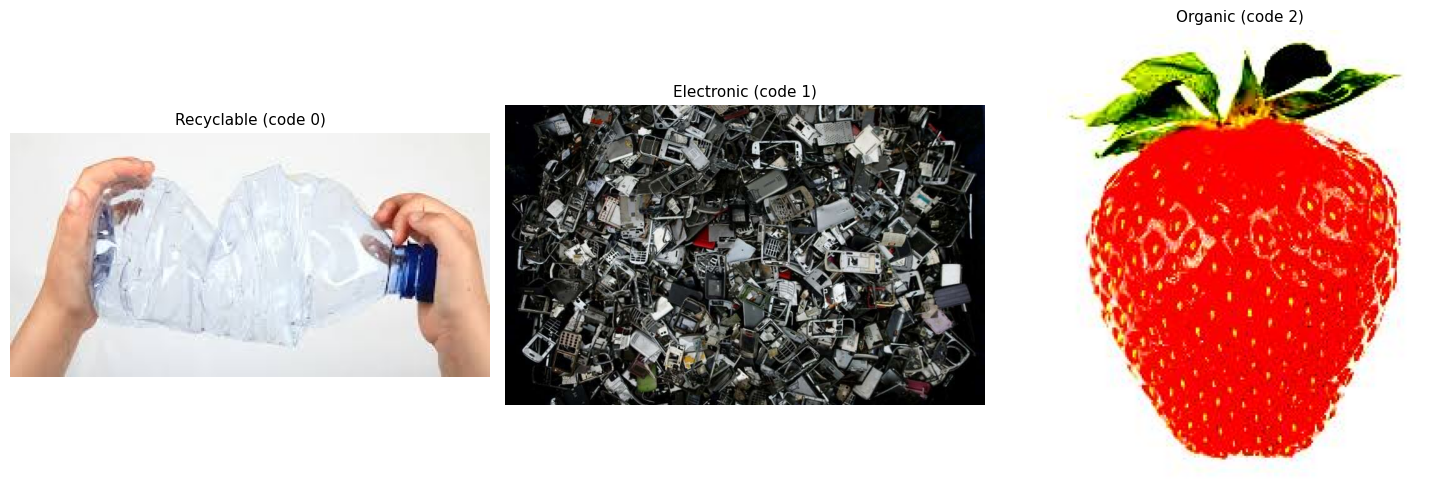

In [ ]:
# cek beberapa sample per kelas
fig, ax = plt.subplots(1, NUM_CLASSES, figsize=(5*NUM_CLASSES, 5))
for i, c in enumerate(CLASSES):
    folder = resolve_folder(c)
    fp = os.path.join(TRAIN_DIR, folder, sorted(os.listdir(os.path.join(TRAIN_DIR, folder)))[0])
    ax[i].imshow(Image.open(fp))
    ax[i].set_title(f'{c} (code {class_to_idx[c]})', fontsize=11)
    ax[i].axis('off')
plt.tight_layout()
plt.show()


## Config & Augmentasi

Karena ini bukan problem wajah, **tidak ada face-cropping** — seluruh gambar dipakai langsung.
Augmentasi dirancang generik untuk pengenalan objek/material:
- Geometric (flip, rotate ringan, shift/scale) — objek sampah bisa difoto dari berbagai sudut
- Color jitter ringan-sedang — variasi pencahayaan foto
- Noise/blur/compression — simulasi variasi kualitas kamera
- CoarseDropout — regularisasi, cegah model overfit ke satu bagian gambar

Dataset train besar (26.527 citra) sehingga **tidak di-cache ke RAM** — gambar dibaca dari
`data_cache` lokal (hasil sel caching sebelumnya) tiap batch, bukan dari Drive langsung.

Config di bawah juga punya beberapa tuas hemat compute (`QUICK_MODE`, `RUN_MODELS`, `RESUME`,
`USE_AMP`) — lihat penjelasan lengkap di catatan "Hemat Runtime & Split Lintas Akun" di atas.


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 15
LR = 1e-4
PATIENCE = 4
N_FOLDS = 3          # dataset besar -> 3 fold cukup representatif & lebih hemat waktu (naikin ke 5 kalau waktu cukup)
SWA_START = 10
SWA_LR = 1e-5
NUM_WORKERS = 2      # Colab (terutama free tier) cuma punya 2 vCPU, jangan set kegedean

USE_AMP = True       # mixed precision -> speedup ~1.5-2x di GPU T4/L4, ga ngorbanin akurasi
RESUME = True        # skip fold yang checkpoint-nya udah ada di SAVE_DIR (buat lanjut abis disconnect)

# --- QUICK_MODE: buat kalau limit GPU udah mepet banget, potong drastis waktu training ---
QUICK_MODE = False   # set True buat run cepat (1 backbone, 1 fold, epoch dikit) demi ngirit compute

# semua backbone yang tersedia buat ensemble
ALL_MODELS = [
    ('convnext_small.fb_in22k_ft_in1k',   'ConvNeXt-S'),
    ('efficientnet_b3',                    'EffNet-B3'),
    ('tf_efficientnetv2_s.in21k_ft_in1k',  'EffNetV2-S'),
]

# --- RUN_MODELS: subset backbone yang mau DILATIH di SESSION/AKUN INI ---
# Kalau kerja bareng tim & split ke beberapa akun Google, tiap akun tinggal
# ganti RUN_MODELS jadi backbone yang beda, ga perlu ngubah apa2 lagi.
# contoh akun A: RUN_MODELS = [ALL_MODELS[0]]  (ConvNeXt-S aja)
#         akun B: RUN_MODELS = [ALL_MODELS[1]]  (EffNet-B3 aja)
#         akun C: RUN_MODELS = [ALL_MODELS[2]]  (EffNetV2-S aja)
RUN_MODELS = ALL_MODELS   # default: latih semua backbone di session ini

if QUICK_MODE:
    N_FOLDS = 1
    NUM_EPOCHS = 8
    SWA_START = 6
    RUN_MODELS = [ALL_MODELS[0]]
    print('QUICK_MODE aktif: 1 backbone x 1 fold x 8 epoch — buat tes cepat / limit compute mepet')

MODELS = RUN_MODELS  # dipakai di sel training di bawah

train_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.15, rotate_limit=20, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.4),
    A.OneOf([
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=25, val_shift_limit=15),
        A.RGBShift(r_shift_limit=12, g_shift_limit=12, b_shift_limit=12),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    ], p=0.5),
    A.OneOf([
        A.GaussNoise(p=1.0),
        A.ISONoise(p=1.0),
        A.ImageCompression(quality_lower=60, quality_upper=100, p=1.0),
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
    ], p=0.3),
    A.CoarseDropout(max_holes=6, max_height=IMG_SIZE//10, max_width=IMG_SIZE//10, fill_value=0, p=0.2),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

val_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])


In [ ]:
class WasteDataset(Dataset):
    def __init__(self, paths, labels=None, tf=None):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        p = self.paths[i]
        img = np.array(Image.open(p).convert('RGB'))
        if self.tf: img = self.tf(image=img)['image']
        return (img, self.labels[i]) if self.labels is not None else img

# mixup & cutmix — regularization tambahan
def mixup(x, y, a=0.4):
    l = np.random.beta(a, a)
    idx = torch.randperm(x.size(0)).to(x.device)
    return l*x + (1-l)*x[idx], y, y[idx], l

def cutmix(x, y, a=1.0):
    l = np.random.beta(a, a)
    idx = torch.randperm(x.size(0)).to(x.device)
    _, _, H, W = x.shape
    r = np.sqrt(1.-l)
    cw, ch = int(W*r), int(H*r)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1, y1 = np.clip(cx-cw//2,0,W), np.clip(cy-ch//2,0,H)
    x2, y2 = np.clip(cx+cw//2,0,W), np.clip(cy+ch//2,0,H)
    x[:,:,y1:y2,x1:x2] = x[idx,:,y1:y2,x1:x2]
    return x, y, y[idx], 1-((x2-x1)*(y2-y1)/(W*H))

def mixed_loss(crit, out, ya, yb, l):
    return l*crit(out, ya) + (1-l)*crit(out, yb)


In [ ]:
def train_epoch(model, loader, crit, opt, dev, scaler=None):
    model.train()
    total_loss, correct, n = 0., 0, 0
    use_amp = scaler is not None
    for imgs, lbls in loader:
        imgs, lbls = imgs.to(dev), lbls.to(dev)
        opt.zero_grad()
        with autocast(enabled=use_amp):
            if random.random() < 0.5:
                fn = mixup if random.random() < 0.5 else cutmix
                imgs, ya, yb, lam = fn(imgs, lbls)
                out = model(imgs)
                loss = mixed_loss(crit, out, ya, yb, lam)
            else:
                out = model(imgs)
                loss = crit(out, lbls)
                ya = lbls
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        total_loss += loss.item()*imgs.size(0)
        _, pred = out.max(1)
        n += lbls.size(0); correct += pred.eq(ya).sum().item()
    return total_loss/n, correct/n

@torch.no_grad()
def evaluate(model, loader, crit, dev, use_amp=False):
    model.eval()
    total_loss, correct, n = 0., 0, 0
    preds, trues = [], []
    for imgs, lbls in loader:
        imgs, lbls = imgs.to(dev), lbls.to(dev)
        with autocast(enabled=use_amp):
            out = model(imgs)
            loss = crit(out, lbls)
        total_loss += loss.item()*imgs.size(0)
        _, pred = out.max(1)
        n += lbls.size(0); correct += pred.eq(lbls).sum().item()
        preds.extend(pred.cpu().numpy()); trues.extend(lbls.cpu().numpy())
    return total_loss/n, correct/n, f1_score(trues, preds, average='macro'), preds, trues


## Training

Strategi: cosine annealing sampai epoch `SWA_START`, lalu switch ke SWA sampai `NUM_EPOCHS`.
SWA nge-average bobot model dari beberapa checkpoint terakhir — hasilnya model yang lebih
"stabil" dan generalize lebih baik (Izmailov 2018), berguna terutama karena hanya 3 fold.


In [ ]:
def get_splits(paths, labels, n_folds):
    if n_folds == 1:
        # QUICK_MODE: 1 hold-out split aja, bukan k-fold beneran
        from sklearn.model_selection import train_test_split
        idx = np.arange(len(paths))
        ti, vi = train_test_split(idx, test_size=0.15, stratify=labels, random_state=42)
        return [(ti, vi)]
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    return list(skf.split(paths, labels))

def train_kfold(mname, dname, paths, labels):
    print(f'\n{"="*60}')
    print(f'{dname} | {N_FOLDS}-fold + SWA' + (' | RESUME on' if RESUME else ''))
    print(f'{"="*60}')

    splits = get_splits(paths, labels, N_FOLDS)
    results, saved = [], []

    for fold, (ti, vi) in enumerate(splits):
        sp = os.path.join(SAVE_DIR, f'{mname.split(".")[0]}_f{fold}.pth')

        # --- RESUME: kalau checkpoint fold ini udah ada, skip training, tinggal load & eval ---
        if RESUME and os.path.exists(sp):
            print(f'\nfold {fold+1}/{N_FOLDS}: checkpoint udah ada ({sp}), SKIP training, cuma eval buat laporan')
            vp, vl = paths[vi], labels[vi]
            vds = WasteDataset(vp, vl, val_tf)
            vloader = DataLoader(vds, batch_size=BATCH_SIZE, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=True)
            model = timm.create_model(mname, pretrained=False, num_classes=NUM_CLASSES)
            model.load_state_dict(torch.load(sp, map_location=device, weights_only=True))
            model = model.to(device)
            crit = nn.CrossEntropyLoss(label_smoothing=0.1)
            _, va, vf, _, _ = evaluate(model, vloader, crit, device, use_amp=USE_AMP)
            print(f'  loaded checkpoint -> val:{va*100:.1f}% f1:{vf:.4f}')
            results.append(vf); saved.append(sp)
            del model; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
            continue

        print(f'\nfold {fold+1}/{N_FOLDS}')
        set_seed(42 + fold)

        tp, tl = paths[ti], labels[ti]
        vp, vl = paths[vi], labels[vi]

        tds = WasteDataset(tp, tl, train_tf)
        vds = WasteDataset(vp, vl, val_tf)

        # weighted sampling utk handle imbalance antar kelas
        cnts = np.bincount(tl, minlength=NUM_CLASSES)
        w = (1./np.maximum(cnts, 1))[tl]
        sampler = WeightedRandomSampler(w, len(w), replacement=True)

        tloader = DataLoader(tds, batch_size=BATCH_SIZE, sampler=sampler,
                             num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
        vloader = DataLoader(vds, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=True)

        model = timm.create_model(mname, pretrained=True, num_classes=NUM_CLASSES).to(device)
        crit = nn.CrossEntropyLoss(label_smoothing=0.1)
        opt = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
        sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=SWA_START)
        swa_model = AveragedModel(model)
        swa_sched = SWALR(opt, swa_lr=SWA_LR)
        scaler = GradScaler(enabled=USE_AMP)

        best_f1, wait = 0., 0

        for ep in range(NUM_EPOCHS):
            tl_, ta = train_epoch(model, tloader, crit, opt, device, scaler=scaler if USE_AMP else None)
            if ep < SWA_START:
                sched.step()
            else:
                swa_model.update_parameters(model)
                swa_sched.step()

            _, va, vf, _, _ = evaluate(model, vloader, crit, device, use_amp=USE_AMP)
            swa = '*' if ep >= SWA_START else ' '
            print(f'  {swa} ep{ep+1:2d} | loss:{tl_:.3f} | val:{va*100:.1f}% f1:{vf:.4f}', end='')

            if vf > best_f1:
                best_f1, wait = vf, 0
                torch.save(model.state_dict(), sp)
                print(' <-- best (saved, bisa di-resume kalau disconnect)')
            else:
                wait += 1
                print(f' (wait {wait})')

            if ep < SWA_START and wait >= PATIENCE:
                print('  early stop -> swa')
                break

        # cek swa model
        update_bn(tloader, swa_model, device=device)
        _, sa, sf, _, _ = evaluate(swa_model, vloader, crit, device, use_amp=USE_AMP)
        print(f'  swa: {sa*100:.1f}% f1:{sf:.4f}')
        if sf > best_f1:
            torch.save(swa_model.module.state_dict(), sp)
            best_f1 = sf
            print('  swa lebih bagus, saved')

        results.append(best_f1)
        saved.append(sp)
        del model, swa_model, opt, sched
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    print(f'\n{dname} avg f1: {np.mean(results):.4f}')
    return saved, results


In [ ]:
# --- run backbone yang ada di RUN_MODELS (subset ALL_MODELS) utk session/akun ini ---
print('backbone yang dilatih di session ini:', [d for _, d in MODELS])
all_saved, all_results = {}, {}
t_start = time.time()

for mname, dname in MODELS:
    t0 = time.time()
    sp, res = train_kfold(mname, dname, all_paths, all_labels)
    all_saved[mname] = sp
    all_results[dname] = res
    print(f'{dname}: {(time.time()-t0)/60:.1f}m\n')

total_min = (time.time() - t_start) / 60
print(f'\ntotal: {total_min:.1f}m')
for n, r in all_results.items():
    print(f'  {n:12s} avg f1={np.mean(r):.4f} | {["{:.3f}".format(x) for x in r]}')


backbone yang dilatih di session ini: ['ConvNeXt-S', 'EffNet-B3', 'EffNetV2-S']

ConvNeXt-S | 3-fold + SWA | RESUME on

fold 1/3: checkpoint udah ada (/content/drive/MyDrive/BDCSATDAT2/saved_models/convnext_small_f0.pth), SKIP training, cuma eval buat laporan


KeyboardInterrupt: 

## Evaluasi per model

KeyError: 'convnext_small.fb_in22k_ft_in1k'

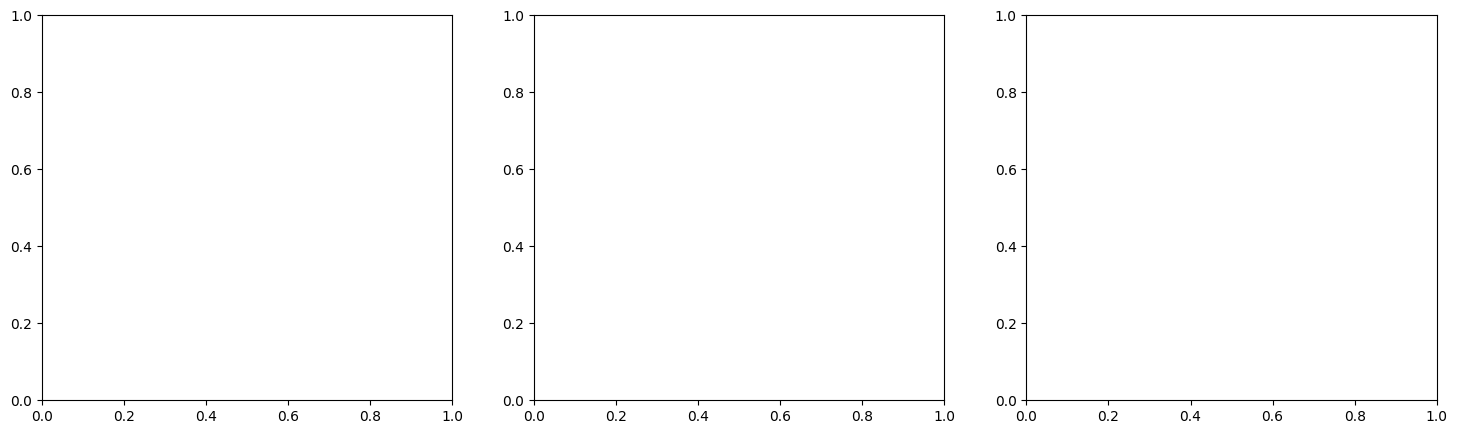

In [ ]:
# confusion matrix dari fold terakhir tiap model (yang dilatih di session ini)
_, val_idx = get_splits(all_paths, all_labels, N_FOLDS)[-1]  # last fold

vp, vl = all_paths[val_idx], all_labels[val_idx]
vds = WasteDataset(vp, vl, val_tf)
vloader = DataLoader(vds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
crit = nn.CrossEntropyLoss(label_smoothing=0.1)

label_names = [f'{c}' for c in CLASSES]  # urutan sesuai code 0,1,2

fig, axes = plt.subplots(1, len(MODELS), figsize=(6*len(MODELS), 5))
for i, (mname, dname) in enumerate(MODELS):
    model = timm.create_model(mname, pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(all_saved[mname][-1], map_location=device, weights_only=True))
    model = model.to(device)
    _, _, f1, preds, trues = evaluate(model, vloader, crit, device)
    cm = confusion_matrix(trues, preds, labels=list(range(NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names,
                yticklabels=label_names, ax=axes[i])
    axes[i].set_title(f'{dname} (f1={f1:.3f})', fontsize=10)
    axes[i].set_xlabel('pred'); axes[i].set_ylabel('true')
    del model; gc.collect()
plt.tight_layout(); plt.show()


In [ ]:
import glob, os, re

# hapus duplikat "(n).pth" utk SEMUA backbone, sisain cuma file tanpa suffix angka
for prefix in ['convnext_small', 'efficientnet_b3', 'tf_efficientnetv2_s']:
    files = glob.glob(os.path.join(SAVE_DIR, f'{prefix}_f*.pth'))
    for f in files:
        base = os.path.basename(f)
        if re.search(r'\(\d+\)\.pth$', base):
            os.remove(f)
            print('deleted:', base)

print('\nsisa checkpoint:')
for prefix in ['convnext_small', 'efficientnet_b3', 'tf_efficientnetv2_s']:
    remaining = sorted(glob.glob(os.path.join(SAVE_DIR, f'{prefix}_f*.pth')))
    print(f'  {prefix}: {len(remaining)} file -> {[os.path.basename(f) for f in remaining]}')

deleted: efficientnet_b3_f2 (3).pth
deleted: efficientnet_b3_f2 (2).pth
deleted: efficientnet_b3_f2 (1).pth
deleted: tf_efficientnetv2_s_f0 (8).pth
deleted: tf_efficientnetv2_s_f0 (7).pth
deleted: tf_efficientnetv2_s_f0 (6).pth
deleted: tf_efficientnetv2_s_f0 (5).pth
deleted: tf_efficientnetv2_s_f0 (4).pth
deleted: tf_efficientnetv2_s_f0 (3).pth
deleted: tf_efficientnetv2_s_f0 (2).pth
deleted: tf_efficientnetv2_s_f0 (1).pth
deleted: tf_efficientnetv2_s_f1 (5).pth
deleted: tf_efficientnetv2_s_f1 (4).pth
deleted: tf_efficientnetv2_s_f1 (3).pth
deleted: tf_efficientnetv2_s_f1 (2).pth
deleted: tf_efficientnetv2_s_f1 (1).pth
deleted: tf_efficientnetv2_s_f2 (7).pth
deleted: tf_efficientnetv2_s_f2 (6).pth
deleted: tf_efficientnetv2_s_f2 (5).pth
deleted: tf_efficientnetv2_s_f2 (4).pth
deleted: tf_efficientnetv2_s_f2 (3).pth
deleted: tf_efficientnetv2_s_f2 (2).pth
deleted: tf_efficientnetv2_s_f2 (1).pth

sisa checkpoint:
  convnext_small: 3 file -> ['convnext_small_f0.pth', 'convnext_small_f1.p

# VALIDATION


In [ ]:
# --- Ensemble selection: bandingin macro F1 di VALIDATION set (versi cepat, 1 fold/backbone) ---
import glob
from sklearn.metrics import f1_score

_, val_idx = get_splits(all_paths, all_labels, N_FOLDS)[-1]
vp, vl = all_paths[val_idx], all_labels[val_idx]
vds = WasteDataset(vp, vl, val_tf)
vloader = DataLoader(vds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

model_probs = {}
for mname, dname in ALL_MODELS:
    prefix = mname.split('.')[0]
    ckpts = sorted(glob.glob(os.path.join(SAVE_DIR, f'{prefix}_f*.pth')))[-1:]  # cuma fold terakhir
    if not ckpts:
        print(f'{dname}: ga ada checkpoint, skip')
        continue
    m = timm.create_model(mname, pretrained=False, num_classes=NUM_CLASSES).to(device)
    m.load_state_dict(torch.load(ckpts[0], map_location=device, weights_only=True))
    m.eval()
    pr = []
    with torch.no_grad():
        for imgs, _ in vloader:
            imgs = imgs.to(device)
            with autocast(enabled=USE_AMP):
                out = m(imgs)
            pr.append(torch.softmax(out, dim=1).float().cpu().numpy())
    model_probs[mname] = np.concatenate(pr)
    del m; gc.collect()
    print(f'{dname}: 1 fold checkpoint dimuat')

def macro_f1_for(subset_mnames):
    probs = np.mean([model_probs[m] for m in subset_mnames], axis=0)
    preds = np.argmax(probs, axis=1)
    return f1_score(vl, preds, average='macro')

all_mnames = list(model_probs.keys())
print(f'\n{"="*50}')
print('macro F1 di validation set (1 fold/backbone):')
print(f'{"="*50}')
for mname, dname in ALL_MODELS:
    if mname in model_probs:
        print(f'  {dname:12s} sendiri     : {macro_f1_for([mname]):.4f}')

print(f'  ensemble semua ({len(all_mnames)}) : {macro_f1_for(all_mnames):.4f}')

weak = 'efficientnet_b3'
subset = [m for m in all_mnames if m != weak]
if len(subset) < len(all_mnames):
    print(f'  ensemble tanpa {weak}: {macro_f1_for(subset):.4f}')

ConvNeXt-S: 1 fold checkpoint dimuat
EffNet-B3: 1 fold checkpoint dimuat
EffNetV2-S: 1 fold checkpoint dimuat

macro F1 di validation set (1 fold/backbone):
  ConvNeXt-S   sendiri     : 0.9815
  EffNet-B3    sendiri     : 0.9670
  EffNetV2-S   sendiri     : 0.9737
  ensemble semua (3) : 0.9806
  ensemble tanpa efficientnet_b3: 0.9818


## Inference — Ensemble + TTA

3 backbone x N_FOLDS model, masing-masing diprediksi 3x (original, hflip, brightness ringan).
Total prediksi di-average jadi satu probabilitas akhir per kelas.


In [ ]:
tta_list = [
    val_tf,  # original
    A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=1.0),
               A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
    A.Compose([A.Resize(IMG_SIZE, IMG_SIZE),
               A.RandomBrightnessContrast(brightness_limit=(0.1,0.1), contrast_limit=(0.1,0.1), p=1.0),
               A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
]

# exclude backbone yg narik turun ensemble (val macro F1: semua=0.9806 vs tanpa EffNet-B3=0.9818)
EXCLUDE_MODELS = ['efficientnet_b3']

# --- scan SAVE_DIR buat semua checkpoint yg ada, ga peduli dilatih di session/akun mana ---
# jadi kalau training di-split ke beberapa akun (lihat catatan di sel awal), sel ini otomatis
# gabungin semua model yg udah selesai dilatih, tinggal jalanin di akun manapun.
found_ckpts = []  # list of (mname, path)
for mname, dname in ALL_MODELS:
    if mname in EXCLUDE_MODELS:
        print(f'{dname:12s}: di-exclude dari ensemble')
        continue
    prefix = mname.split('.')[0]
    matches = sorted(glob.glob(os.path.join(SAVE_DIR, f'{prefix}_f*.pth')))
    for mp in matches:
        found_ckpts.append((mname, mp))
    print(f'{dname:12s}: {len(matches)} checkpoint ditemukan di SAVE_DIR')

if not found_ckpts:
    raise RuntimeError('Ga ada checkpoint di SAVE_DIR sama sekali — training dulu sebelum inference.')

n_models = len(found_ckpts)
print(f'\nensemble: {n_models} model checkpoint x {len(tta_list)} tta = {n_models*len(tta_list)} predictions')

all_probs = []
for mname, mp in found_ckpts:
    m = timm.create_model(mname, pretrained=False, num_classes=NUM_CLASSES)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True))
    m = m.to(device); m.eval()
    for ttf in tta_list:
        ds = WasteDataset(test_paths, tf=ttf)
        dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
        pr = []
        with torch.no_grad():
            for x in dl:
                x = x.to(device)
                with autocast(enabled=USE_AMP):
                    out = m(x)
                pr.append(torch.softmax(out, dim=1).float().cpu().numpy())
        all_probs.append(np.concatenate(pr))
    del m; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

ens_prob = np.mean(all_probs, axis=0)
ens_pred_code = np.argmax(ens_prob, axis=1)          # kode numerik 0/1/2
ens_pred_name = [idx_to_class[p] for p in ens_pred_code]  # nama label, buat sanity check

print('\ndistribusi prediksi:')
for c in CLASSES:
    n = ens_pred_name.count(c)
    print(f'  {c:12s} (code {class_to_idx[c]}): {n:4d} ({n/len(ens_pred_name)*100:.1f}%)')

ConvNeXt-S  : 3 checkpoint ditemukan di SAVE_DIR
EffNet-B3   : di-exclude dari ensemble
EffNetV2-S  : 3 checkpoint ditemukan di SAVE_DIR

ensemble: 6 model checkpoint x 3 tta = 18 predictions

distribusi prediksi:
  Recyclable   (code 0):  510 (35.0%)
  Electronic   (code 1):  197 (13.5%)
  Organic      (code 2):  751 (51.5%)


## Submission

In [ ]:
# --- susun submission sesuai format panitia: kolom id, predicted (numerik) ---
sub = pd.DataFrame({'id': test_ids, 'predicted': ens_pred_code})

# kalau ada template.csv dari panitia, urutkan & validasi persis sesuai urutan id-nya
if os.path.exists(TEMPLATE):
    tmpl = pd.read_csv(TEMPLATE)
    tmpl_id_col = tmpl.columns[0]  # biasanya 'id'
    # samain tipe data id (string vs int) sebelum reindex
    sub['id'] = sub['id'].astype(str)
    tmpl[tmpl_id_col] = tmpl[tmpl_id_col].astype(str)
    sub = sub.set_index('id').loc[tmpl[tmpl_id_col].values].reset_index()
    sub.columns = ['id', 'predicted']
    assert len(sub) == len(tmpl), 'row count mismatch dengan template'
    assert (sub['id'].values == tmpl[tmpl_id_col].astype(str).values).all(), 'urutan id ga match template'
    print('urutan & jumlah baris tervalidasi sesuai template.csv')
else:
    print('WARNING: template.csv ga ketemu di BASE_DIR — submission diurutin numerik dari nama file test aja.')
    print('         pastiin urutan ini emang sama persis dengan submission.csv panitia sebelum upload.')

assert set(sub['predicted'].unique()).issubset({0, 1, 2}), 'kode label harus 0/1/2'

sub_name = f'submission_{TEAM_NAME}.csv'
sub_path = os.path.join(BASE_DIR, sub_name)
sub.to_csv(sub_path, index=False)
sub.to_csv(f'/content/{sub_name}', index=False)

print(sub.head(10).to_string(index=False))

# confidence check
conf = np.max(ens_prob, axis=1)
print(f'\nconfidence: mean={np.mean(conf):.3f}, >80%={np.sum(conf>0.8)}, <50%={np.sum(conf<0.5)}')

try:
    from google.colab import files
    files.download(f'/content/{sub_name}')
except: pass

print(f'saved: {sub_path}')
print(f'total training time: {total_min:.1f}m')


urutan & jumlah baris tervalidasi sesuai template.csv
id  predicted
 1          2
 2          2
 3          2
 4          1
 5          0
 6          2
 7          2
 8          0
 9          1
10          2

confidence: mean=0.875, >80%=1264, <50%=10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved: /content/drive/MyDrive/BDCSATDAT2/submission_ThreeSrikandi.csv


NameError: name 'total_min' is not defined

coba heat map

In [ ]:
import glob
from sklearn.metrics import confusion_matrix
import seaborn as sns

_, val_idx = get_splits(all_paths, all_labels, N_FOLDS)[-1]
vp, vl = all_paths[val_idx], all_labels[val_idx]
vds = WasteDataset(vp, vl, val_tf)
vloader = DataLoader(vds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
crit = nn.CrossEntropyLoss(label_smoothing=0.1)

eval_models = [(m, d) for m, d in ALL_MODELS if m not in EXCLUDE_MODELS]
fig, axes = plt.subplots(1, len(eval_models), figsize=(6*len(eval_models), 5))
if len(eval_models) == 1: axes = [axes]

for i, (mname, dname) in enumerate(eval_models):
    prefix = mname.split('.')[0]
    ckpts = sorted(glob.glob(os.path.join(SAVE_DIR, f'{prefix}_f*.pth')))
    model = timm.create_model(mname, pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(ckpts[-1], map_location=device, weights_only=True))
    model = model.to(device)
    _, _, f1, preds, trues = evaluate(model, vloader, crit, device, use_amp=USE_AMP)
    cm = confusion_matrix(trues, preds, labels=list(range(NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[i])
    axes[i].set_title(f'{dname} (f1={f1:.3f})', fontsize=10)
    axes[i].set_xlabel('pred'); axes[i].set_ylabel('true')
    del model; gc.collect()
plt.tight_layout(); plt.show()

NameError: name 'get_splits' is not defined

## BUAT CEK BAGUS APA NGGAK


In [ ]:
print('distribusi kelas di TRAIN:')
for c in CLASSES:
    n = np.sum(all_labels == class_to_idx[c])
    print(f'  {c:12s}: {n:6d} ({n/len(all_labels)*100:.1f}%)')

print('\ndistribusi prediksi di TEST (ensemble):')
for c in CLASSES:
    n = ens_pred_name.count(c)
    print(f'  {c:12s}: {n:4d} ({n/len(ens_pred_name)*100:.1f}%)')

distribusi kelas di TRAIN:
  Recyclable  :   9999 (37.7%)
  Electronic  :   3961 (14.9%)
  Organic     :  12567 (47.4%)

distribusi prediksi di TEST (ensemble):
  Recyclable  :  510 (35.0%)
  Electronic  :  197 (13.5%)
  Organic     :  751 (51.5%)


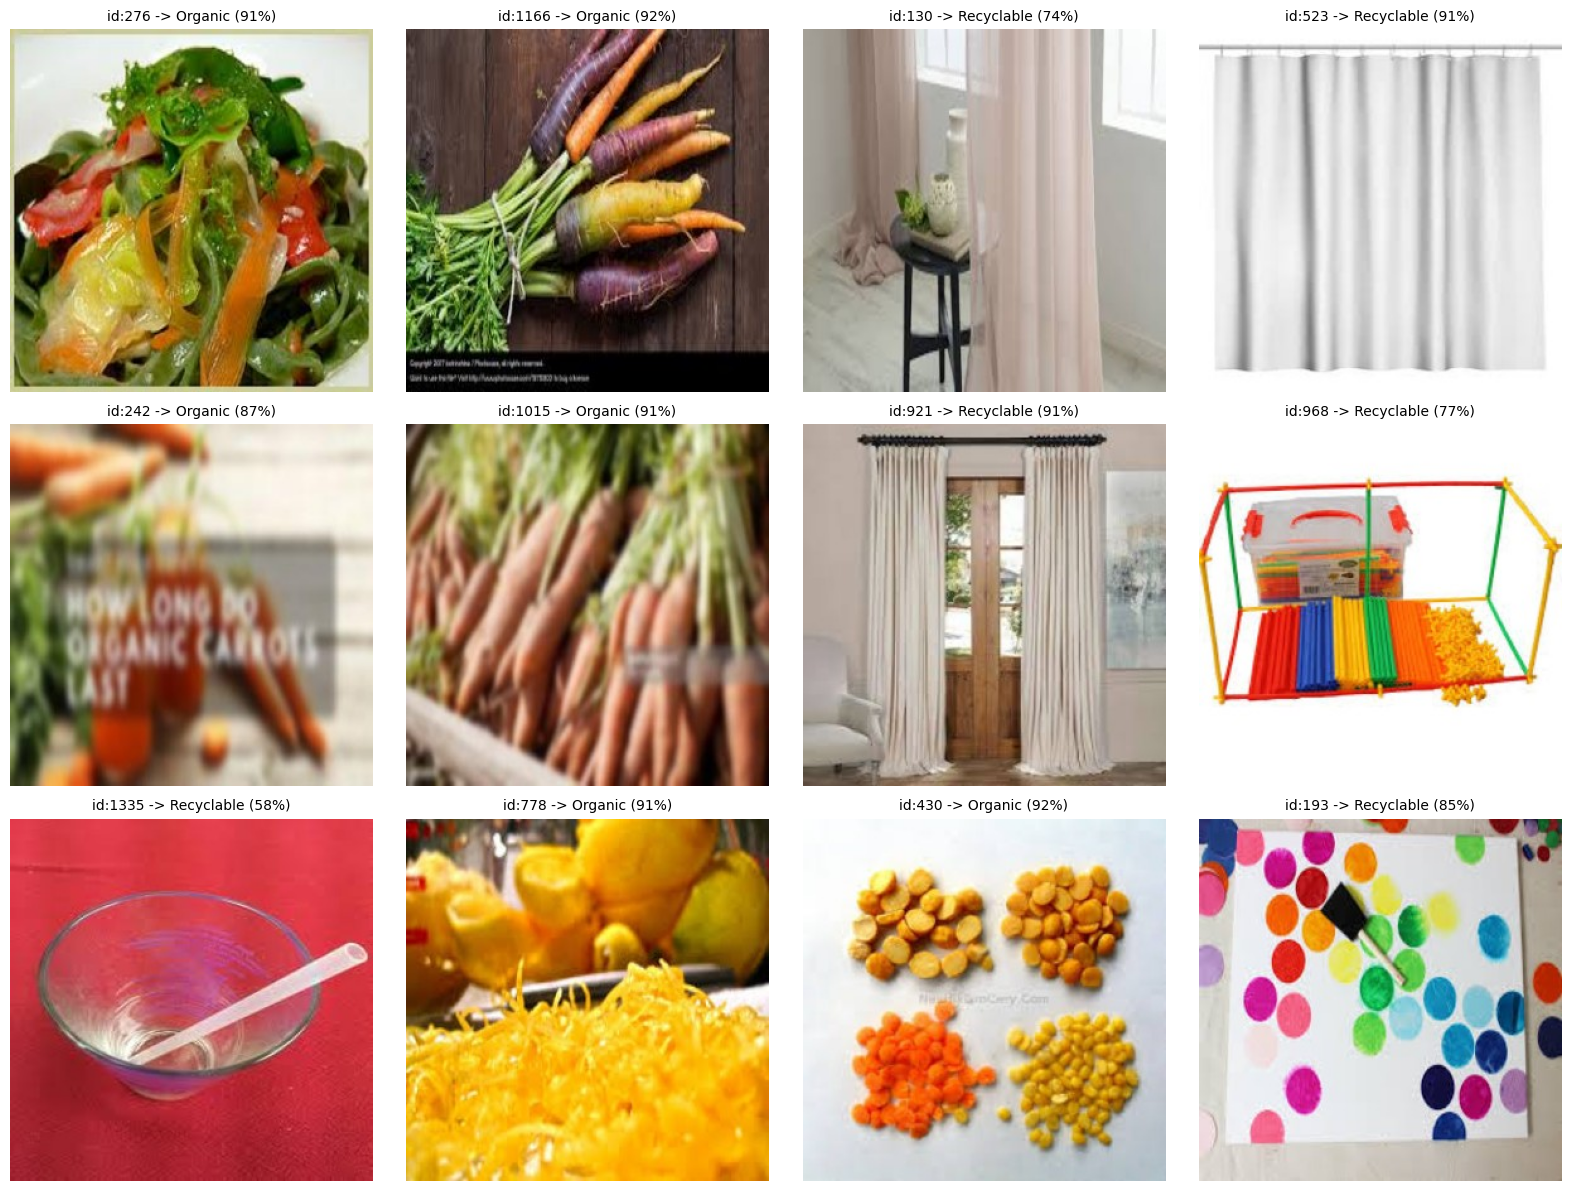

In [ ]:
import random
random.seed(1)
sample_idx = random.sample(range(len(test_paths)), 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, idx in zip(axes.flat, sample_idx):
    img = Image.open(test_paths[idx])
    pred_name = ens_pred_name[idx]
    conf = ens_prob[idx].max()
    ax.imshow(img)
    ax.set_title(f'id:{test_ids[idx]} -> {pred_name} ({conf*100:.0f}%)', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

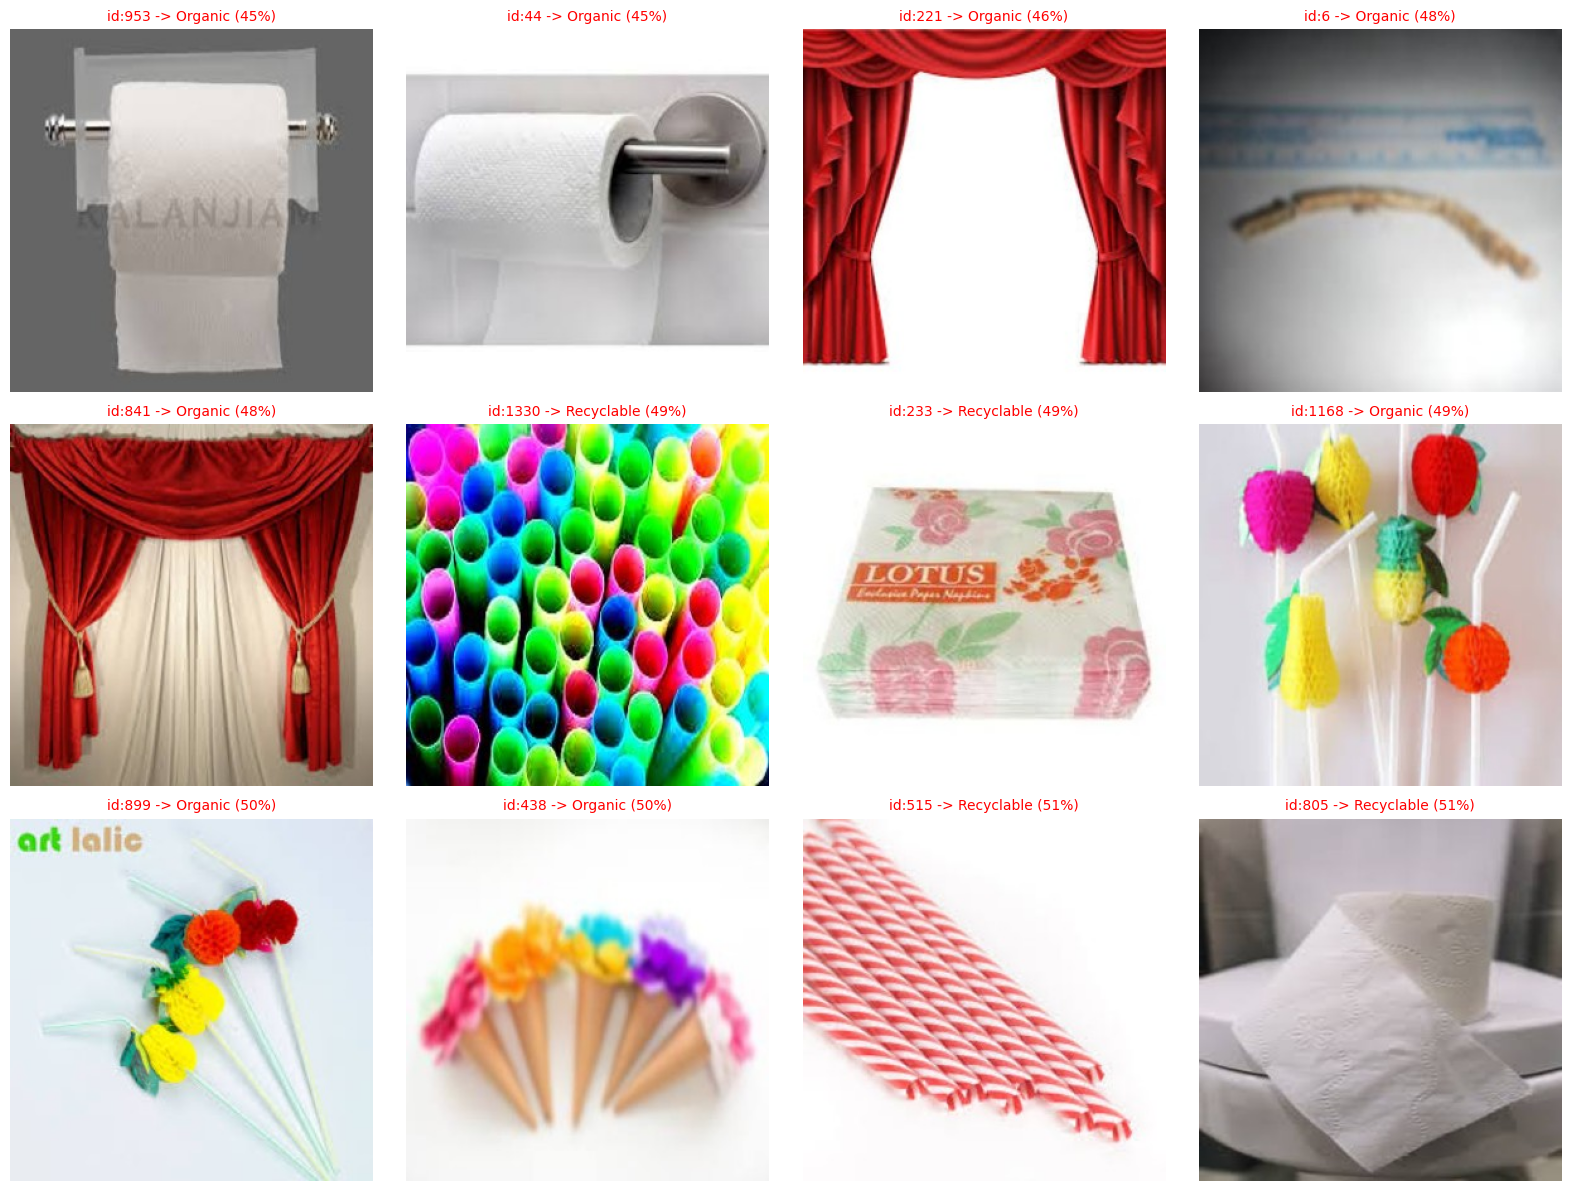

In [ ]:
low_conf_idx = np.argsort(ens_prob.max(axis=1))[:12]  # 12 gambar paling ga yakin

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, idx in zip(axes.flat, low_conf_idx):
    img = Image.open(test_paths[idx])
    pred_name = ens_pred_name[idx]
    conf = ens_prob[idx].max()
    ax.imshow(img)
    ax.set_title(f'id:{test_ids[idx]} -> {pred_name} ({conf*100:.0f}%)', fontsize=10, color='red')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Ringkasan

| Teknik | Detail |
|--------|--------|
| Preprocessing | Resize 224x224, tanpa crop khusus (bukan problem wajah) |
| Augmentasi | Geometric ringan-sedang, color jitter, noise/blur, coarse dropout |
| Backbone | ConvNeXt-S, EffNet-B3, EffNetV2-S (pretrained IN-21k, transfer learning sesuai Batasan poin 6) |
| Training | 3-fold stratified CV, weighted sampling, mixup/cutmix, label smoothing |
| Regularisasi | Label smoothing 0.1, grad clip, SWA (Izmailov 2018) |
| Inference | Ensemble semua checkpoint yang ditemukan di SAVE_DIR x 3 TTA |
| Metrik | Macro-averaged F1-Score (dicek tiap fold via `f1_score(..., average='macro')`) |
| Submission | `id, predicted` (kode 0/1/2), nama file `submission_NamaTim.csv`, urutan match template panitia |
| **Hemat compute** | AMP mixed precision, local disk image cache, resume-from-checkpoint, `QUICK_MODE`, split training lintas akun via `RUN_MODELS` |

**Catatan kepatuhan Batasan kompetisi:**
- Hanya pakai informasi visual dari citra yang disediakan (poin 2)
- Augmentasi hanya di Data Latih, tidak menyentuh Data Uji (poin 3)
- Data Uji cuma dipakai untuk prediksi akhir, bukan training/tuning (poin 4)
- Backbone pretrained publik (bukan dilatih ulang dari data kompetisi lain) — didokumentasikan di sini utk laporan akhir (poin 6)
